<a href="https://colab.research.google.com/github/Romanzilla/ML/blob/main/%D0%9B%D0%A04_%D0%9D%D0%B0%D0%B4%D1%96%D0%B9%D0%BA%D0%BE_3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №4. Регресійні моделі: глибоке дослідження

**Датасет:** Car Price Prediction Multiple Linear Regression  
https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?select=CarPrice_Assignment.csv

**Мета роботи:** виконати підготовку даних, побудувати та порівняти регресійні моделі для прогнозування ціни автомобіля, оцінити їх якість і проаналізувати отримані результати.


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import kagglehub
import os

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, PowerTransformer, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)

## 1. Завантаження та первинний аналіз даних

Завантажити датасет та виконати його первинний огляд:
- визначити кількість об'єктів і ознак;
- переглянути назви стовпців;
- визначити типи даних;
- визначити цільову змінну;
- вивести основні статистичні характеристики даних.


In [ ]:
path = kagglehub.dataset_download("hellbuoy/car-price-prediction")

df = pd.read_csv(os.path.join(path, "CarPrice_Assignment.csv"))

display(df.head())

Using Colab cache for faster access to the 'car-price-prediction' dataset.


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


In [ ]:
df.shape

(205, 26)

In [ ]:
df.columns

Index(['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration',
       'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase',
       'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype',
       'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke',
       'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg',
       'price'],
      dtype='object')

In [ ]:
df.dtypes

,0
car_ID,int64
symboling,int64
CarName,object
fueltype,object
aspiration,object
doornumber,object
carbody,object
drivewheel,object
enginelocation,object
wheelbase,float64


In [ ]:
df.describe()

,car_ID,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,103.000000,0.834146,98.756585,174.049268,65.907805,53.724878,2555.565854,126.907317,3.329756,3.255415,10.142537,104.117073,5125.121951,25.219512,30.751220,13276.710571
std,59.322565,1.245307,6.021776,12.337289,2.145204,2.443522,520.680204,41.642693,0.270844,0.313597,3.972040,39.544167,476.985643,6.542142,6.886443,7988.852332
min,1.000000,-2.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,52.000000,0.000000,94.500000,166.300000,64.100000,52.000000,2145.000000,97.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7788.000000
50%,103.000000,1.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,154.000000,2.000000,102.400000,183.100000,66.900000,55.500000,2935.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16503.000000
max,205.000000,3.000000,120.900000,208.100000,72.300000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,288.000000,6600.000000,49.000000,54.000000,45400.000000


In [ ]:
print("\nЦільова змінна: price")


Цільова змінна: price


## 2. Перевірка якості даних

Перевірити:
- наявність пропущених значень;
- наявність повних дублікатів;
- кількість унікальних значень в ознаках.

Під час аналізу врахувати, що `car_ID` є унікальним ідентифікатором автомобіля і сам по собі не повинен використовуватися для визначення дублікатів за змістовими характеристиками.


In [ ]:
print("Кількість пропущених значень:")
display(df.isna().sum().sort_values(ascending=False))

print("Повні дублікати:", df.duplicated().sum())

print(
    "Дублікати без урахування car_ID:",
    df.drop(columns="car_ID").duplicated().sum()
)

print("Кількість унікальних значень у кожній ознаці:")
display(df.nunique().sort_values())

Кількість пропущених значень:


,0
car_ID,0
symboling,0
CarName,0
fueltype,0
aspiration,0
doornumber,0
carbody,0
drivewheel,0
enginelocation,0
wheelbase,0


Повні дублікати: 0
Дублікати без урахування car_ID: 0
Кількість унікальних значень у кожній ознаці:


,0
fueltype,2
aspiration,2
doornumber,2
enginelocation,2
drivewheel,3
carbody,5
symboling,6
cylindernumber,7
enginetype,7
fuelsystem,8


## 3. Робота з car_ID

Зберегти `car_ID` окремо для подальшої ідентифікації автомобілів у результатах прогнозування.  
Не використовувати `car_ID` як ознаку під час навчання моделей.


In [ ]:
df['CarName'].value_counts()

,count
CarName,
peugeot 504,6
toyota corolla,6
toyota corona,6
subaru dl,4
mitsubishi outlander,3
...,...
volkswagen super beetle,1
volkswagen rabbit custom,1
volvo 245,1


In [ ]:
ids = df["car_ID"].copy()

df_model = df.copy()
df_model["brand"] = (
    df_model["CarName"]
    .str.lower()
    .str.split()
    .str[0]
    .replace({
        "maxda": "mazda",
        "porcshce": "porsche",
        "toyouta": "toyota",
        "vokswagen": "volkswagen",
        "vw": "volkswagen",
    })
)
df_model = df_model.drop(columns=["car_ID", "CarName"])

In [ ]:
df_model

,symboling,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,carlength,carwidth,...,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price,brand
0,3,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0,alfa-romero
1,3,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0,alfa-romero
2,1,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,...,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0,alfa-romero
3,2,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,...,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0,audi
4,2,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,...,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0,audi
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,-1,gas,std,four,sedan,rwd,front,109.1,188.8,68.9,...,mpfi,3.78,3.15,9.5,114,5400,23,28,16845.0,volvo
201,-1,gas,turbo,four,sedan,rwd,front,109.1,188.8,68.8,...,mpfi,3.78,3.15,8.7,160,5300,19,25,19045.0,volvo
202,-1,gas,std,four,sedan,rwd,front,109.1,188.8,68.9,...,mpfi,3.58,2.87,8.8,134,5500,18,23,21485.0,volvo
203,-1,diesel,turbo,four,sedan,rwd,front,109.1,188.8,68.9,...,idi,3.01,3.40,23.0,106,4800,26,27,22470.0,volvo


## 4. Дослідження розподілів числових ознак

Дослідити розподіли числових ознак:
- побудувати відповідні графіки;
- обчислити коефіцієнти асиметрії;
- визначити ознаки з найбільш вираженою асиметрією;
- коротко прокоментувати отримані результати.


,skewness
symboling,0.211072
wheelbase,1.050214
carlength,0.155954
carwidth,0.904003
carheight,0.063123
curbweight,0.681398
enginesize,1.947655
boreratio,0.020156
stroke,-0.689705
compressionratio,2.610862


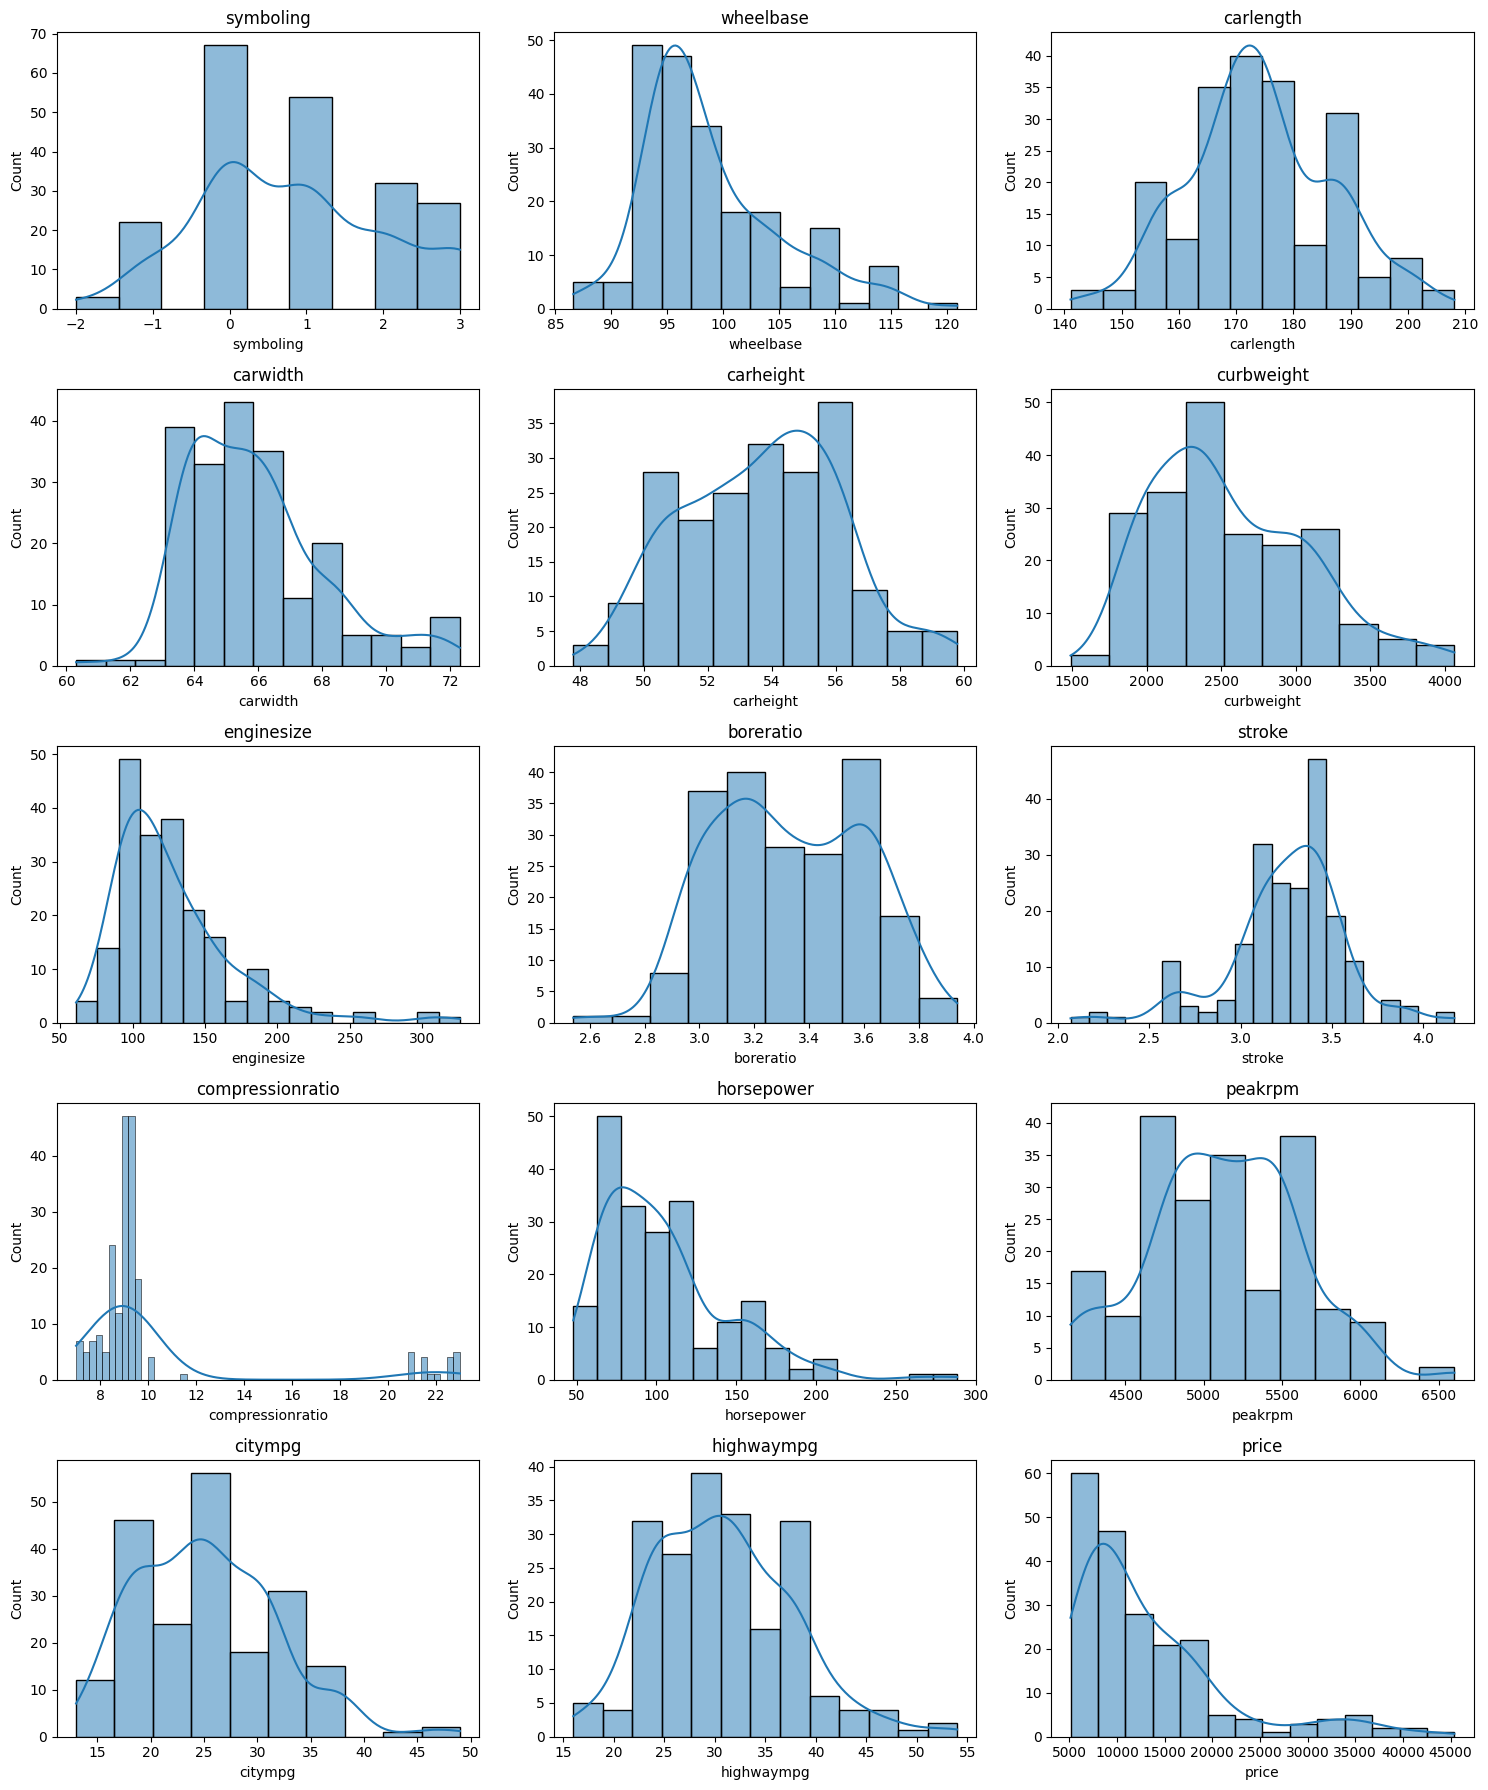

In [ ]:
numeric_initial = df_model.select_dtypes(include=np.number).columns.tolist()
skew_initial = df_model[numeric_initial].skew()

display(skew_initial.to_frame("skewness"))

n_cols = 3
n_rows = int(np.ceil(len(numeric_initial) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 3.6 * n_rows))
axes = np.array(axes).reshape(-1)

for ax, col in zip(axes, numeric_initial):
    sns.histplot(df_model[col], kde=True, ax=ax)
    ax.set_title(col)

for ax in axes[len(numeric_initial):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
skew_df = skew_initial.to_frame("skewness")
skew_df["abs_skew"] = skew_df["skewness"].abs()
skew_sorted = skew_df.sort_values(by="abs_skew", ascending=False)

highly_skewed = skew_sorted[skew_sorted["abs_skew"] > 1][["skewness"]]

print("Ознаки з найбільш вираженою асиметрією (|skew| > 1):")
display(highly_skewed)

Ознаки з найбільш вираженою асиметрією (|skew| > 1):


,skewness
compressionratio,2.610862
enginesize,1.947655
price,1.777678
horsepower,1.405310
wheelbase,1.050214


Характер розподілу метрик автомобілів:
1. Симетричний (нормальний): Параметри boreratio, carheight, peakrpm, carlength і symboling розподілені рівномірно (skew: 0.02–0.21) та мають чітку дзвоноподібну форму.
2. Правобічний (із викидами в більшу сторону): Для price, horsepower, enginesize, wheelbase та compressionratio характерна сильна правобічна асиметрія. Більшість машин належить до середнього сегмента, але довгий правий хвіст формують поодинокі преміальні чи специфічні моделі.
3. Лівобічний (із викидами в меншу сторону): Показник stroke має помірну лівобічну асиметрію (skew: -0.69) з подовженим лівим хвостом.

## 5. Формування train/test вибірок

Відокремити цільову змінну `price` від ознак та розділити дані на:
- навчальну вибірку — 80%;
- тестову вибірку — 20%.

Забезпечити відтворюваність поділу.  
Окремо зберегти `car_ID` для об'єктів, які потрапили до train і test.

**Важливо:** усі подальші параметри передобробки даних визначати тільки за навчальною вибіркою.


In [ ]:
X = df_model.drop(columns="price")

y = df_model["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
)

id_train = ids.loc[X_train.index]
id_test = ids.loc[X_test.index]

print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (164, 24) Test: (41, 24)


## 6. Аналіз та обробка викидів

Для неперервних числових ознак навчальної вибірки:
- визначити потенційні викиди методом IQR;
- вивести кількість потенційних викидів для кожної ознаки;
- обґрунтувати спосіб їх обробки.

Для невеликого набору даних не видаляти автоматично всі рядки з викидами. Використати обмеження крайніх значень межами, визначеними за навчальною вибіркою.

Цільову змінну `price` не використовувати для визначення меж викидів.  
До тестової вибірки застосувати ті самі межі, які були отримані за train.


In [ ]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()

lower_bounds = {}
upper_bounds = {}
outliers_count = {}

for col in numeric_features:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1


    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    lower_bounds[col] = lower_bound
    upper_bounds[col] = upper_bound

    is_outlier = (X_train[col] < lower_bound) | (X_train[col] > upper_bound)
    outliers_count[col] = is_outlier.sum()

print("Кількість потенційних викидів у навчальній вибірці (train):")
for col, count in outliers_count.items():
    print(f"{col:<20} : {count}")

for col in numeric_features:

    X_train[col] = X_train[col].clip(lower=lower_bounds[col], upper=upper_bounds[col])

    X_test[col] = X_test[col].clip(lower=lower_bounds[col], upper=upper_bounds[col])

print("\nКрайні значення в X_train та X_test успішно обмежено.")

Кількість потенційних викидів у навчальній вибірці (train):
symboling            : 0
wheelbase            : 6
carlength            : 0
carwidth             : 10
carheight            : 0
curbweight           : 0
enginesize           : 7
boreratio            : 1
stroke               : 16
compressionratio     : 20
horsepower           : 7
peakrpm              : 2
citympg              : 0
highwaympg           : 1

Крайні значення в X_train та X_test успішно обмежено.


Чому ми обмежуємо викиди, а не видаляємо їх:

1. Збереження даних: на малих датасетах видалення рядків призводить до втрати важливої інформації.
2. Реальність аномалій: екстремальні значення (наприклад, потужні двигуни люксових авто) є закономірністю, а не технічним збоєм. Модель повинна вміти їх обробляти.
3. Стабільність моделі: заміна аномалій граничними значеннями не дозволяє екстремальним числам спотворювати прогнози, але зберігає сам факт високого чи низького рівня показника.
4. Чистота експерименту: для імітації реальних умов межі зрізання розраховуються лише на навчальному наборі (X_train) і дзеркально переносяться на тестовий (X_test).

## 7. Аналіз кореляцій та відбір ознак

За навчальною вибіркою:
- побудувати матрицю кореляцій числових ознак;
- знайти пари ознак із сильною кореляцією, для яких `|r| > 0.85`;
- для кожної такої пари залишити одну ознаку;
- під час вибору врахувати силу зв'язку кожної ознаки з цільовою змінною `price`;
- вивести список сильно корельованих пар та перелік ознак, які видаляються.

Із тестової вибірки видалити ті самі ознаки.  
Не використовувати тестову вибірку для прийняття рішення про відбір ознак.


In [ ]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()

corr_with_target = X_train[numeric_features].corrwith(y_train).abs()

corr_matrix = X_train[numeric_features].corr()
display(corr_matrix)

upper_tri = corr_matrix.abs().where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

high_corr_pairs = []
features_to_drop = set()

print("Пари ознак із сильною кореляцією (|r| > 0.85):")

for feature1 in upper_tri.columns:
    for feature2 in upper_tri.index[upper_tri[feature1] > 0.85]:

        if feature1 in features_to_drop or feature2 in features_to_drop:
            continue

        pair_corr = upper_tri.loc[feature2, feature1]
        high_corr_pairs.append((feature2, feature1, pair_corr))

        corr_f1 = corr_with_target[feature1]
        corr_f2 = corr_with_target[feature2]

        if corr_f1 < corr_f2:
            dropped, kept = feature1, feature2
        else:
            dropped, kept = feature2, feature1

        features_to_drop.add(dropped)

        print(f"Пара: '{feature2}' та '{feature1}' (|r| = {pair_corr:.3f})")
        print(f"  '{kept}' — зв'язок із price: {corr_with_target[kept]:.3f} -> залишаємо")
        print(f"  '{dropped}' — зв'язок із price: {corr_with_target[dropped]:.3f} -> видаляємо")

features_to_drop = list(features_to_drop)

print("\nПідсумковий перелік ознак, які будуть видалені:")
print(features_to_drop)

if features_to_drop:
    X_train = X_train.drop(columns=features_to_drop)
    X_test = X_test.drop(columns=features_to_drop)
    print("\nОзнаки успішно видалено з X_train та X_test.")
else:
    print("\nПар із |r| > 0.85 не знайдено. Жодна ознака не видаляється.")

,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg
symboling,1.000000,-0.529886,-0.335504,-0.188751,-0.537134,-0.184052,-0.019755,-0.069261,-0.050779,-0.062137,0.129422,0.282002,-0.109415,-0.029365
wheelbase,-0.529886,1.000000,0.867043,0.776252,0.583080,0.744827,0.480384,0.436310,0.191481,0.002648,0.334326,-0.377828,-0.410237,-0.494257
carlength,-0.335504,0.867043,1.000000,0.838946,0.464789,0.865988,0.655872,0.558943,0.141090,-0.054099,0.556342,-0.320005,-0.630014,-0.670892
carwidth,-0.188751,0.776252,0.838946,1.000000,0.240133,0.858047,0.708562,0.541332,0.170756,-0.049741,0.626537,-0.226593,-0.632576,-0.666401
carheight,-0.537134,0.583080,0.464789,0.240133,1.000000,0.246243,0.015726,0.130297,-0.011801,0.087016,-0.124711,-0.318205,0.003616,-0.062927
curbweight,-0.184052,0.744827,0.865988,0.858047,0.246243,1.000000,0.848682,0.626735,0.123413,-0.093797,0.756743,-0.280823,-0.752704,-0.796620
enginesize,-0.019755,0.480384,0.655872,0.708562,0.015726,0.848682,1.000000,0.613366,0.161773,-0.088349,0.830252,-0.247532,-0.684215,-0.687571
boreratio,-0.069261,0.436310,0.558943,0.541332,0.130297,0.626735,0.613366,1.000000,-0.111057,-0.081739,0.558497,-0.273495,-0.564362,-0.563640
stroke,-0.050779,0.191481,0.141090,0.170756,-0.011801,0.123413,0.161773,-0.111057,1.000000,-0.058567,0.054362,-0.042811,-0.003004,-0.000669
compressionratio,-0.062137,0.002648,-0.054099,-0.049741,0.087016,-0.093797,-0.088349,-0.081739,-0.058567,1.000000,-0.318740,-0.158121,0.461834,0.425007


Пари ознак із сильною кореляцією (|r| > 0.85):
Пара: 'wheelbase' та 'carlength' (|r| = 0.867)
  'carlength' — зв'язок із price: 0.652 -> залишаємо
  'wheelbase' — зв'язок із price: 0.504 -> видаляємо
Пара: 'carlength' та 'curbweight' (|r| = 0.866)
  'curbweight' — зв'язок із price: 0.824 -> залишаємо
  'carlength' — зв'язок із price: 0.652 -> видаляємо
Пара: 'carwidth' та 'curbweight' (|r| = 0.858)
  'curbweight' — зв'язок із price: 0.824 -> залишаємо
  'carwidth' — зв'язок із price: 0.732 -> видаляємо
Пара: 'citympg' та 'highwaympg' (|r| = 0.964)
  'highwaympg' — зв'язок із price: 0.716 -> залишаємо
  'citympg' — зв'язок із price: 0.711 -> видаляємо

Підсумковий перелік ознак, які будуть видалені:
['wheelbase', 'citympg', 'carwidth', 'carlength']

Ознаки успішно видалено з X_train та X_test.


## 8. Підготовка числових і категоріальних ознак

Розділити ознаки на:
- неперервні числові;
- дискретну числову ознаку `symboling`;
- категоріальні.

Для неперервних числових ознак виконати послідовно:
1. перетворення Yeo–Johnson для зменшення асиметрії;
2. масштабування за допомогою StandardScaler.

Для `symboling` виконати масштабування без Yeo–Johnson.

Категоріальні ознаки закодувати методом One-Hot Encoding. Передбачити коректну обробку категорій у test, яких не було у train.

Усі перетворення об'єднати в єдиний механізм передобробки даних, який навчається тільки на `X_train`.


In [ ]:
discrete_features = ['symboling']

continuous_features = X_train.select_dtypes(
    include=np.number
).columns.drop(discrete_features).tolist()

categorical_features = X_train.select_dtypes(
    include='object'
).columns.tolist()

print("Неперервні числові ознаки:", continuous_features)
print("Дискретна числова ознака:", discrete_features)
print("Категоріальні ознаки:", categorical_features)

continuous_pipeline = Pipeline([
    ('yeo_johnson', PowerTransformer(method='yeo-johnson')),
    ('scaler', StandardScaler())
])

discrete_pipeline = Pipeline([
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('continuous', continuous_pipeline, continuous_features),
    ('discrete', discrete_pipeline, discrete_features),
    ('categorical', categorical_pipeline, categorical_features)
])

X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("\nРозмір X_train після передобробки:", X_train_processed.shape)
print("Розмір X_test після передобробки:", X_test_processed.shape)

Неперервні числові ознаки: ['carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'highwaympg']
Дискретна числова ознака: ['symboling']
Категоріальні ознаки: ['fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem', 'brand']

Розмір X_train після передобробки: (164, 69)
Розмір X_test після передобробки: (41, 69)


## 9. Перевірка трансформації числових ознак

Перевірити результат трансформації неперервних числових ознак:
- застосувати до train ту саму послідовність перетворень, яка буде використана в моделях;
- повторно обчислити коефіцієнти асиметрії;
- порівняти їх із початковими значеннями;
- зробити короткий висновок щодо ефективності трансформації.


In [ ]:
skew_before = X_train[continuous_features].skew()

X_continuous_transformed = (
    preprocessor.named_transformers_['continuous']
    .transform(X_train[continuous_features])
)

X_continuous_transformed = pd.DataFrame(
    X_continuous_transformed,
    columns=continuous_features,
    index=X_train.index
)

skew_after = X_continuous_transformed.skew()

skew_comparison = pd.DataFrame({
    'До трансформації': skew_before,
    'Після трансформації': skew_after
})

skew_comparison['|Асиметрія до|'] = skew_before.abs()
skew_comparison['|Асиметрія після|'] = skew_after.abs()

display(skew_comparison.round(4))

,До трансформації,Після трансформації,|Асиметрія до|,|Асиметрія після|
carheight,0.0282,-0.0052,0.0282,0.0052
curbweight,0.7124,0.0499,0.7124,0.0499
enginesize,0.9624,0.0448,0.9624,0.0448
boreratio,0.0630,-0.0059,0.0630,0.0059
stroke,-0.3976,0.0158,0.3976,0.0158
compressionratio,0.0557,0.0049,0.0557,0.0049
horsepower,0.8507,0.0663,0.8507,0.0663
peakrpm,0.0398,-0.0036,0.0398,0.0036
highwaympg,0.2438,-0.0122,0.2438,0.0122


Трансформація Yeo–Johnson є ефективним інструментом для нормалізації розподілу неперервних числових даних шляхом зменшення їхньої асиметрії. Порівнюючи показники асиметрії до та після застосування цього методу, можна наочно оцінити успішність математичного перетворення. Зниження абсолютного значення коефіцієнта свідчить про те, що розподіл конкретної ознаки наблизився до симетричного (нормального) вигляду. При цьому якість оптимізації аналізується індивідуально для кожного окремого показника в наборі даних.


## 10. Побудова регресійних моделей

Побудувати та навчити такі моделі:
- Linear Regression;
- Ridge Regression;
- Lasso Regression;
- Random Forest Regressor;
- Gradient Boosting Regressor;
- Support Vector Regressor (SVR).

Для кожної моделі створити єдиний Pipeline, який містить:
1. попередню обробку ознак;
2. відповідну регресійну модель.

Використати однакову схему підготовки даних для коректного порівняння моделей.


In [ ]:
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Lasso Regression': Lasso(alpha=0.1, max_iter=20000),
    'Random Forest': RandomForestRegressor(
        n_estimators=200, random_state=42
    ),
    'Gradient Boosting': GradientBoostingRegressor(
        random_state=42
    ),
    'SVR': SVR(kernel='rbf')
}

pipelines = {}

for name, model in models.items():
    pipelines[name] = Pipeline([
        ('preprocessing', clone(preprocessor)),
        ('model', model)
    ])

    pipelines[name].fit(X_train, y_train)
    print(f'{name}: модель навчена')

Linear Regression: модель навчена
Ridge Regression: модель навчена
Lasso Regression: модель навчена
Random Forest: модель навчена
Gradient Boosting: модель навчена
SVR: модель навчена


## 11. Оцінювання якості моделей

Для кожної моделі:
- виконати навчання на тренувальній вибірці;
- отримати прогноз для тестової вибірки;
- обчислити метрики **R², MAE, MSE та MAPE**.

`MAPE` подати у відсотках.

Результати всіх моделей об'єднати в одну порівняльну таблицю та впорядкувати за значенням R² від найбільшого до найменшого.

Під час інтерпретації врахувати:
- R² — чим більше, тим краще;
- MAE, MSE, MAPE — чим менше, тим краще.


In [ ]:
results = []
predictions = {}

for name, pipeline in pipelines.items():
    y_pred = pipeline.predict(X_test)
    predictions[name] = y_pred

    results.append({
        'Модель': name,
        'R²': r2_score(y_test, y_pred),
        'MAE': mean_absolute_error(y_test, y_pred),
        'MSE': mean_squared_error(y_test, y_pred),
        'MAPE (%)': mean_absolute_percentage_error(
            y_test, y_pred
        ) * 100
    })

results_df = pd.DataFrame(results).sort_values(
    by='R²', ascending=False
).reset_index(drop=True)

display(results_df.round(4))

,Модель,R²,MAE,MSE,MAPE (%)
0,Random Forest,0.9547,1332.5062,3.578897e+06,9.7530
1,Gradient Boosting,0.9304,1727.4037,5.492942e+06,12.0502
2,Lasso Regression,0.8804,2113.2646,9.444610e+06,15.5222
3,Linear Regression,0.8794,2156.0911,9.518262e+06,16.3764
4,Ridge Regression,0.8537,2368.3914,1.154979e+07,18.2029
5,SVR,-0.0997,5696.7770,8.681724e+07,36.0277


Для оцінювання моделей застосували чотири показники: R², MAE, MSE та MAPE. Результати відсортовано за зменшенням R², щоб полегшити порівняння.
Оцінювати точність прогнозів слід за такими критеріями:

• R² (коефіцієнт детермінації) має бути максимальним, оскільки вище значення вказує на краще пояснення дисперсії даних.

• MAE, MSE та MAPE мають бути мінімальними, адже нижчі значення свідчать про меншу помилку моделі.


## 12. Пояснення вибору типу моделі

Пояснити, чому класифікаційна модель, наприклад Logistic Regression, не підходить для безпосереднього прогнозування неперервної ціни автомобіля.

Зазначити, до якого типу задачі належить прогнозування `price` та чому моделі, використані в роботі, відповідають цій задачі.


Прогнозування вартості автомобіля є класичною задачею регресії, оскільки цільова змінна (price) є безперервною числовою величиною. Для її розв'язання підходять такі регресійні моделі, як Linear Regression, Ridge, Lasso, Random Forest Regressor, Gradient Boosting Regressor та SVR, які спеціалізуються на передбаченні конкретних числових значень.
Натомість Logistic Regression є алгоритмом класифікації, який визначає належність об'єкта до певних категорій, а не прогнозує точну ціну. Щоб застосувати її в цій задачі, довелося б штучно розділити ціновий діапазон на окремі класи (наприклад, «дешеві», «середні», «дорогі»), що повністю змінило б початкову постановку задачі.

## 13. Візуальне порівняння прогнозів

Для кожної побудованої моделі зобразити співвідношення:
- фактичних значень `price`;
- прогнозованих значень `price`.

Додати лінію ідеального прогнозу та проаналізувати, наскільки близько до неї розташовані прогнозовані значення. Звернути увагу на великі відхилення.


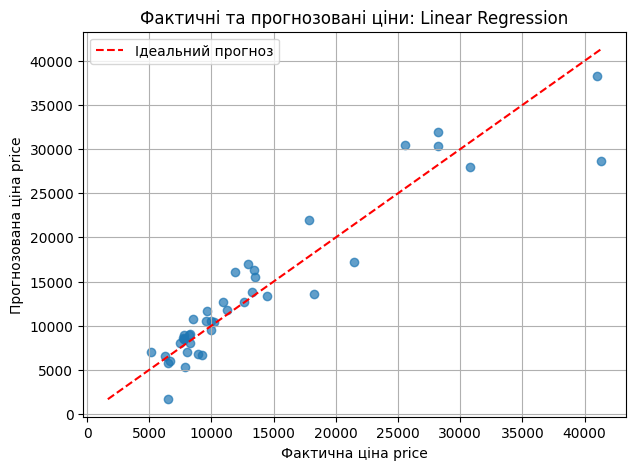

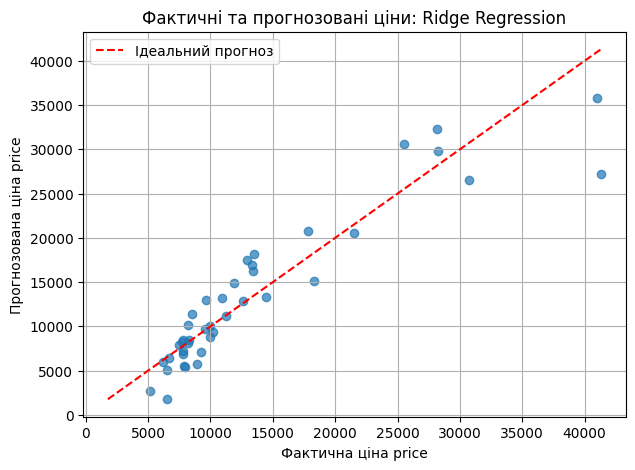

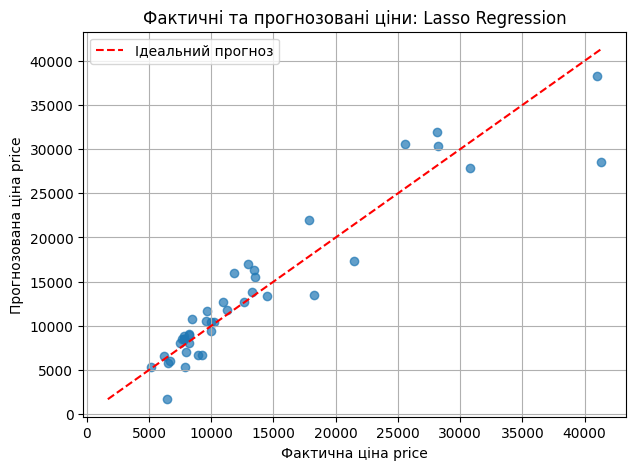

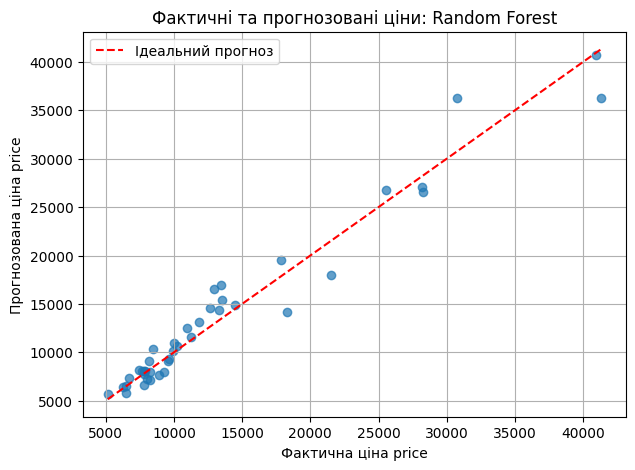

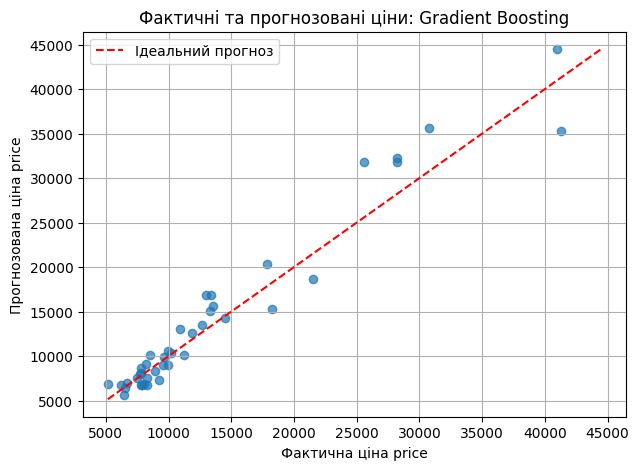

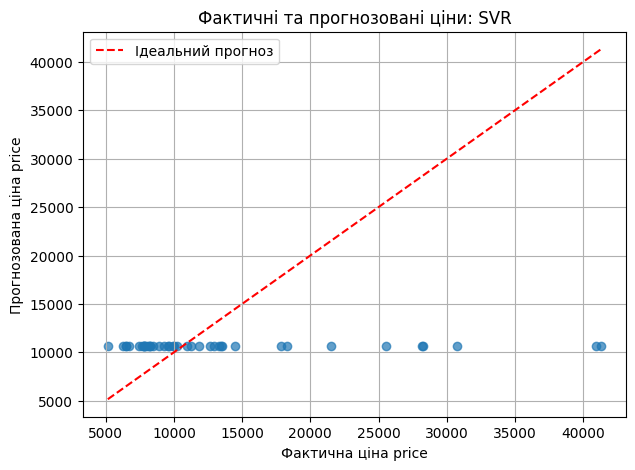

In [ ]:
for name, y_pred in predictions.items():
    plt.figure(figsize=(7, 5))

    plt.scatter(y_test, y_pred, alpha=0.7)

    min_price = min(y_test.min(), y_pred.min())
    max_price = max(y_test.max(), y_pred.max())

    plt.plot(
        [min_price, max_price],
        [min_price, max_price],
        'r--',
        label='Ідеальний прогноз'
    )

    plt.xlabel('Фактична ціна price')
    plt.ylabel('Прогнозована ціна price')
    plt.title(f'Фактичні та прогнозовані ціни: {name}')
    plt.legend()
    plt.grid(True)
    plt.show()


Ці графіки ілюструють точність прогнозування цін на автомобілі через зіставлення їх фактичної та розрахункової вартості. Лінія ідеального прогнозу є орієнтиром: що ближче до неї розташовані точки, то вища точність моделі. І навпаки — значні відхилення вказують на суттєві похибки. Завдяки такій візуалізації можна порівнювати різні моделі та легко виявляти автівки з найбільшою різницею між очікуваною та реальною ціною.

## 14. Прогноз для 10 автомобілів

Випадково вибрати 10 автомобілів із тестової вибірки.

За допомогою моделі Random Forest отримати для них прогноз ціни та сформувати таблицю з такими даними:
- `car_ID`;
- фактична ціна;
- прогнозована ціна;
- абсолютна помилка;
- абсолютна відсоткова помилка.

Прокоментувати отримані результати.


In [ ]:
sample_size = min(10, len(X_test))

sample_indices = X_test.sample(
    n=sample_size, random_state=17
).index

X_sample = X_test.loc[sample_indices]
y_actual = y_test.loc[sample_indices]

rf_model = pipelines['Random Forest']
y_pred_sample = rf_model.predict(X_sample)

comparison_10 = pd.DataFrame({
    'car_ID': id_test.loc[sample_indices],
    'Фактична ціна': y_actual,
    'Прогнозована ціна': y_pred_sample
})

comparison_10['Абсолютна помилка'] = (
    comparison_10['Фактична ціна']
    - comparison_10['Прогнозована ціна']
).abs()

comparison_10['Абсолютна відсоткова помилка (%)'] = (
    comparison_10['Абсолютна помилка']
    / comparison_10['Фактична ціна'].abs()
) * 100

display(comparison_10.round(2))

print(
    'Середня абсолютна помилка:',
    round(comparison_10['Абсолютна помилка'].mean(), 2)
)

print(
    'Середня відсоткова помилка (%):',
    round(
        comparison_10['Абсолютна відсоткова помилка (%)'].mean(),
        2
    )
)

,car_ID,Фактична ціна,Прогнозована ціна,Абсолютна помилка,Абсолютна відсоткова помилка (%)
69,70,28176.0,27097.09,1078.91,3.83
79,80,7689.0,8098.54,409.54,5.33
18,19,5151.0,5732.60,581.60,11.29
154,155,7898.0,8086.51,188.51,2.39
195,196,13415.0,16942.63,3527.63,26.30
202,203,21485.0,17968.65,3516.35,16.37
164,165,8238.0,7921.58,316.43,3.84
16,17,41315.0,36252.35,5062.65,12.25
147,148,10198.0,10644.75,446.75,4.38
55,56,10945.0,12514.85,1569.85,14.34


Середня абсолютна помилка: 1669.82
Середня відсоткова помилка (%): 10.03


Для десяти випадково обраних автомобілів було розраховано прогнозну вартість за допомогою моделі Random Forest Regressor. Щоб оцінити точність алгоритму, для кожного авто визначили дві метрики: абсолютну та абсолютну відсоткову похибки.
Низькі значення цих показників свідчать про високу точність моделі — тобто прогнозована ціна є максимально близькою до реальної вартості. Загальну якість роботи моделі на всій вибірці оцінюють за допомогою середнього значення цих похибок.

In [ ]:
# Порівняємо R² на тренувальній і тестовій вибірках для оцінки можливого перенавчання
overfitting_results = []

for name, pipeline in pipelines.items():
    train_pred = pipeline.predict(X_train)
    test_pred = pipeline.predict(X_test)

    train_r2 = r2_score(y_train, train_pred)
    test_r2 = r2_score(y_test, test_pred)

    overfitting_results.append({
        'Модель': name,
        'R² train': train_r2,
        'R² test': test_r2,
        'Різниця R²': train_r2 - test_r2
    })

overfitting_df = pd.DataFrame(
    overfitting_results
).sort_values(
    by='Різниця R²', ascending=False
).reset_index(drop=True)

display(overfitting_df.round(4))

,Модель,R² train,R² test,Різниця R²
0,Ridge Regression,0.9482,0.8537,0.0945
1,Linear Regression,0.9597,0.8794,0.0803
2,Lasso Regression,0.9597,0.8804,0.0794
3,Gradient Boosting,0.9932,0.9304,0.0628
4,Random Forest,0.9847,0.9547,0.0301
5,SVR,-0.1082,-0.0997,-0.0084


## 15. Висновки

Сформулювати підсумкові висновки за результатами роботи.

У висновках:
- порівняти якість усіх моделей;
- проаналізувати R², MAE, MSE і MAPE;
- зазначити, яка модель показала найкращі результати за отриманими метриками;
- прокоментувати величину похибок;
- звернути увагу на можливі ознаки перенавчання;
- коротко оцінити вплив попередньої обробки даних на результати моделювання.


Дослідження присвячено побудові моделей машинного навчання для прогнозування цін на автомобілі. Завдяки єдиній системі попередньої обробки даних (масштабуванню та кодуванню ознак) було забезпечено об'єктивне порівняння шести регресійних підходів: від лінійних моделей до ансамблів (Random Forest, Gradient Boosting) та SVR. Якість прогнозів оцінювалася за допомогою стандартних метрик (R^2, MAE, MSE, MAPE) та графічного аналізу залишків для 10 тестових авто. Зіставлення результатів на тренувальній і тестовій вибірках допомогло оцінити похибки та виявити ризики перенавчання, що дозволило чітко визначити фінальну модель-лідера.

## Загальні вимоги до виконання

- Не використовувати тестову вибірку для визначення меж викидів, кореляційного відбору ознак, навчання трансформерів, масштабування або кодування категорій.
- Усі параметри передобробки мають визначатися тільки за навчальною вибіркою.
- Фінальні метрики моделей обчислювати на тестовій вибірці.
- Не використовувати `car_ID` як предиктор.
- Не видаляти спостереження або ознаки без пояснення причини.
- До кожного основного етапу додати короткий змістовний висновок.
- У підсумкових висновках спиратися на отримані метрики та графіки.
